In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix

df = pd.read_csv(
    r"C:\Users\krist\Downloads\school stuff\PROJ\Firewall-Action-Classification-System-main\Firewall-Action-Classification-System-main\data\log2_cleaned.csv"
)

print(df.head())

   Source Port  Destination Port  NAT Source Port  NAT Destination Port  \
0        57222                53            54587                    53   
1        56258              3389            56258                  3389   
2         6881             50321            43265                 50321   
3        50553              3389            50553                  3389   
4        50002               443            45848                   443   

  Action  Bytes  Bytes Sent  Bytes Received  Packets  Elapsed Time (sec)  \
0  allow    177          94              83        2                  30   
1  allow   4768        1600            3168       19                  17   
2  allow    238         118             120        2                1199   
3  allow   3327        1438            1889       15                  17   
4  allow  25358        6778           18580       31                  16   

   pkts_sent  pkts_received  
0          1              1  
1         10              9  
2 

In [4]:
%pip install pandas numpy matplotlib seaborn

  Using cached pandas-3.0.6-cp315-cp315-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp315-cp315-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp315-cp315-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.0.6-cp315-cp315-win_amd64.whl (9.8 MB)
Using cached numpy-2.5.4-cp315-cp315-win_amd64.whl (12.7 MB)
Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3

In [11]:
df.isna().sum()

Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port    0
Action                  0
Bytes                   0
Bytes Sent              0
Bytes Received          0
Packets                 0
Elapsed Time (sec)      0
pkts_sent               0
pkts_received           0
dtype: int64

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 57170 entries, 0 to 57169
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Source Port           57170 non-null  int64
 1   Destination Port      57170 non-null  int64
 2   NAT Source Port       57170 non-null  int64
 3   NAT Destination Port  57170 non-null  int64
 4   Action                57170 non-null  str  
 5   Bytes                 57170 non-null  int64
 6   Bytes Sent            57170 non-null  int64
 7   Bytes Received        57170 non-null  int64
 8   Packets               57170 non-null  int64
 9   Elapsed Time (sec)    57170 non-null  int64
 10  pkts_sent             57170 non-null  int64
 11  pkts_received         57170 non-null  int64
dtypes: int64(11), str(1)
memory usage: 5.2 MB


In [14]:
df.describe()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
count,57170.000000,57170.000000,57170.000000,57170.000000,5.717000e+04,5.717000e+04,5.717000e+04,5.717000e+04,57170.000000,57170.000000,57170.000000
mean,50532.499738,8052.147035,22048.739549,3054.123491,1.113147e+05,2.564701e+04,8.566766e+04,1.177065e+02,75.116547,47.279255,70.427200
std,13880.680957,16513.145167,22141.986286,10363.545911,6.015189e+06,4.098545e+06,2.637029e+06,5.495436e+03,322.519323,3446.210063,2380.254144
min,0.000000,0.000000,0.000000,0.000000,6.000000e+01,6.000000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
25%,49450.000000,53.000000,0.000000,0.000000,7.000000e+01,7.000000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
50%,54013.000000,443.000000,16362.500000,53.000000,1.930000e+02,9.400000e+01,9.000000e+01,2.000000e+00,26.000000,1.000000,1.000000
75%,58574.000000,445.000000,41883.750000,443.000000,1.139000e+03,5.080000e+02,6.690000e+02,1.000000e+01,31.000000,5.000000,4.000000
max,65534.000000,65535.000000,65535.000000,65535.000000,1.269359e+09,9.484772e+08,3.208818e+08,1.036116e+06,10824.000000,747520.000000,327208.000000


In [15]:
df.shape

(57170, 12)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df = df.drop_duplicates()

In [18]:
#new df after dropping duplicates
df.duplicated().sum()

np.int64(0)

In [19]:
df.shape

(57170, 12)

In [20]:
#Check invalid or inconsistent values
print(df.nunique())
print(df['Action'].value_counts(dropna=False))

Source Port             22724
Destination Port         3273
NAT Source Port         29152
NAT Destination Port     2533
Action                      4
Bytes                   10724
Bytes Sent               6683
Bytes Received           8814
Packets                  1116
Elapsed Time (sec)        915
pkts_sent                 749
pkts_received             922
dtype: int64
Action
allow         37439
drop          11635
deny           8042
reset-both       54
Name: count, dtype: int64


In [21]:
#Check for infinite values

print("Infinite values:")
print(np.isinf(df.select_dtypes(include='number')).sum())

Infinite values:
Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port    0
Bytes                   0
Bytes Sent              0
Bytes Received          0
Packets                 0
Elapsed Time (sec)      0
pkts_sent               0
pkts_received           0
dtype: int64


In [22]:
print(
    (df['Bytes'] == df['Bytes Sent'] + df['Bytes Received']).value_counts()
)

True    57170
Name: count, dtype: int64


In [23]:
df['Action'].value_counts()

Action
allow         37439
drop          11635
deny           8042
reset-both       54
Name: count, dtype: int64

In [24]:
df['Action']=df['Action'].str.strip().str.lower()

In [25]:
print(df['Action'].value_counts(normalize=True) * 100)

Action
allow         65.487144
drop          20.351583
deny          14.066818
reset-both     0.094455
Name: proportion, dtype: float64


In [26]:
df.isnull().sum()

Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port    0
Action                  0
Bytes                   0
Bytes Sent              0
Bytes Received          0
Packets                 0
Elapsed Time (sec)      0
pkts_sent               0
pkts_received           0
dtype: int64

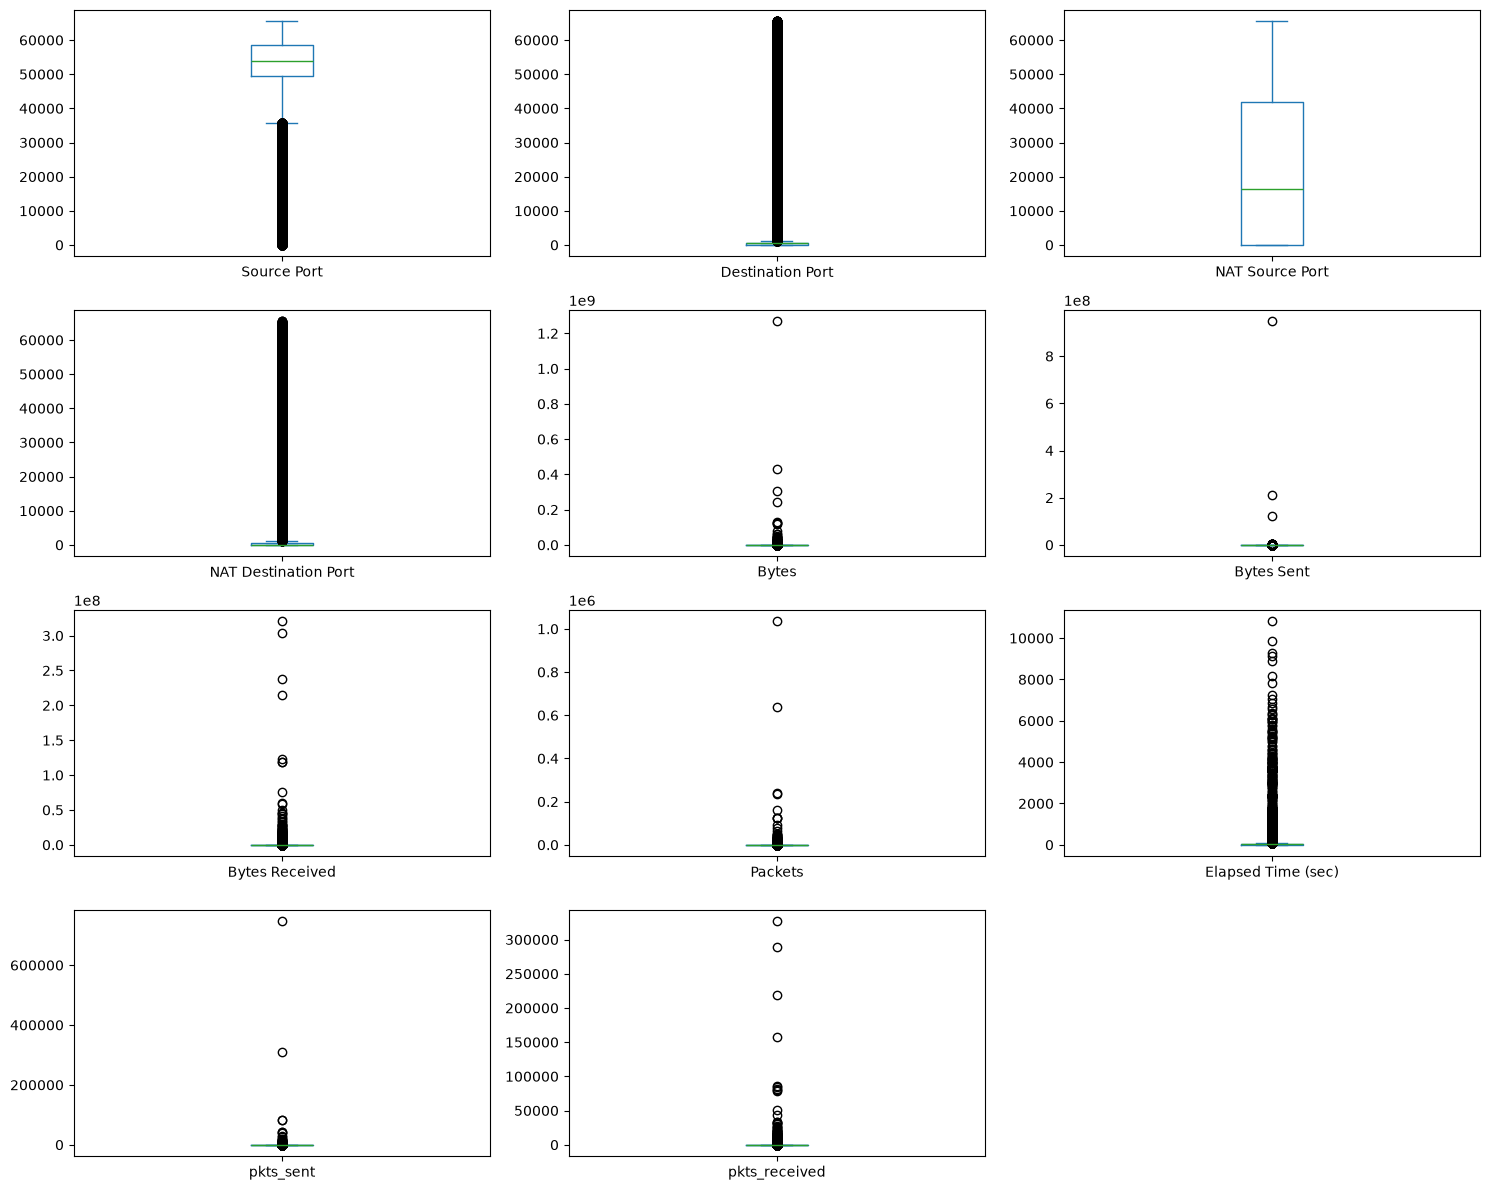

In [27]:
#Visualization

numeric_df=df.select_dtypes(include=['int64','float64'])

numeric_df.plot(
    kind='box',
    subplots=True,
    layout=(4,3),
    figsize=(15,12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

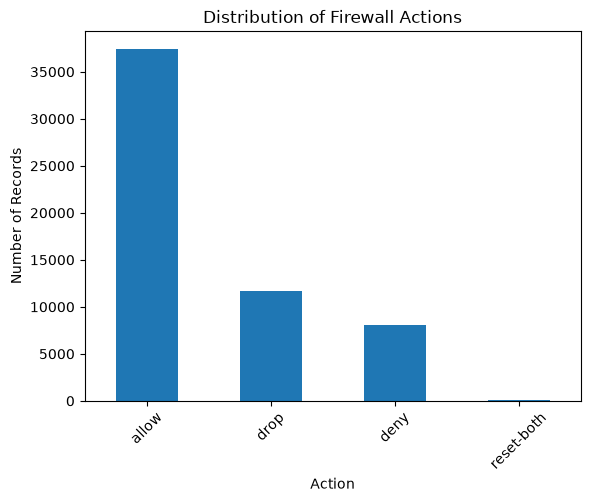

In [28]:
df['Action'].value_counts().plot(kind='bar')

plt.title('Distribution of Firewall Actions')
plt.xlabel('Action')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.show()

In [29]:
#correlation matrix

correlation_matrix=numeric_df.corr()

print(correlation_matrix)

                      Source Port  Destination Port  NAT Source Port  \
Source Port              1.000000         -0.308678         0.098560   
Destination Port        -0.308678          1.000000        -0.205541   
NAT Source Port          0.098560         -0.205541         1.000000   
NAT Destination Port    -0.053903          0.538467         0.152741   
Bytes                   -0.001257         -0.003513         0.009014   
Bytes Sent              -0.001605          0.002960         0.001603   
Bytes Received          -0.000372         -0.012614         0.018070   
Packets                 -0.003761         -0.004008         0.010778   
Elapsed Time (sec)      -0.071835          0.063689         0.121991   
pkts_sent               -0.002750         -0.000498         0.005957   
pkts_received           -0.004701         -0.008533         0.016258   

                      NAT Destination Port     Bytes  Bytes Sent  \
Source Port                      -0.053903 -0.001257   -0.001605   

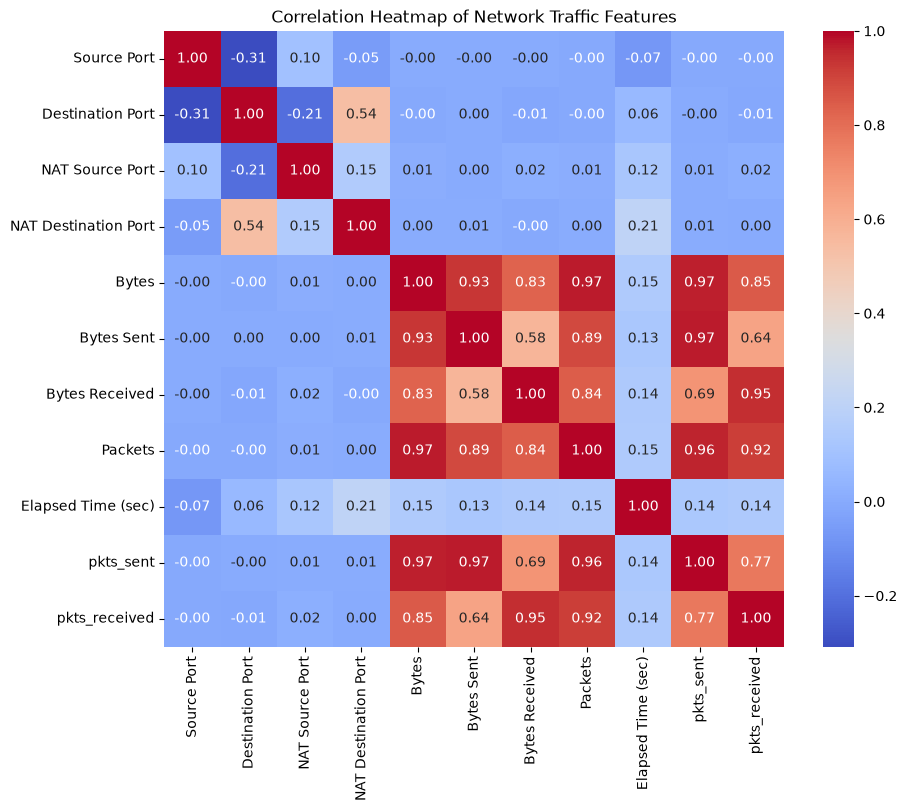

In [30]:
#corr heatmap

plt.figure(figsize=(10,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
    )
plt.title('Correlation Heatmap of Network Traffic Features')
plt.show()

In [31]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -

In [34]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp315-cp315-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.1-cp315-cp315-win_amd64.whl.metadata (7.7 kB)
Using cached statsmodels-0.15.0-cp315-cp315-win_amd64.whl (11.4 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached wrapt-2.5.1-cp315-cp315-win_amd64.whl (106 kB)

   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
  

In [35]:
#Check multicollinearity using VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_features=numeric_df.drop(
    columns=['Bytes', 'Packets']
)

X_vif= add_constant(vif_features)

vif_data=pd.DataFrame()

vif_data['Feature']=X_vif.columns

vif_data['VIF']=[
    variance_inflation_factor(X_vif.values,i)
    for i in range(X_vif.shape[1])
]

print(vif_data)

                Feature        VIF
0                 const   1.000000
1           Source Port   1.136480
2      Destination Port   1.783081
3       NAT Source Port   1.169963
4  NAT Destination Port   1.658590
5            Bytes Sent  57.521984
6        Bytes Received  11.453854
7    Elapsed Time (sec)   1.092727
8             pkts_sent  85.919713
9         pkts_received  24.203995


In [36]:
X=df.drop('Action', axis=1)
y=df['Action']

In [37]:
print(X)

       Source Port  Destination Port  NAT Source Port  NAT Destination Port  \
0            57222                53            54587                    53   
1            56258              3389            56258                  3389   
2             6881             50321            43265                 50321   
3            50553              3389            50553                  3389   
4            50002               443            45848                   443   
...            ...               ...              ...                   ...   
57165        51710             43069            65147                 43069   
57166        63691                80            13237                    80   
57167        50964                80            13485                    80   
57168        54871               445                0                     0   
57169        54870               445                0                     0   

         Bytes  Bytes Sent  Bytes Received  Packets

In [38]:
print(y)

0        allow
1        allow
2        allow
3        allow
4        allow
         ...  
57165    allow
57166    allow
57167    allow
57168     drop
57169     drop
Name: Action, Length: 57170, dtype: str


In [39]:
X_df=pd.DataFrame(X, columns=X.columns)
y_df=pd.DataFrame(y, columns=['Action'])

print(X_df)
print(y_df)

       Source Port  Destination Port  NAT Source Port  NAT Destination Port  \
0            57222                53            54587                    53   
1            56258              3389            56258                  3389   
2             6881             50321            43265                 50321   
3            50553              3389            50553                  3389   
4            50002               443            45848                   443   
...            ...               ...              ...                   ...   
57165        51710             43069            65147                 43069   
57166        63691                80            13237                    80   
57167        50964                80            13485                    80   
57168        54871               445                0                     0   
57169        54870               445                0                     0   

         Bytes  Bytes Sent  Bytes Received  Packets

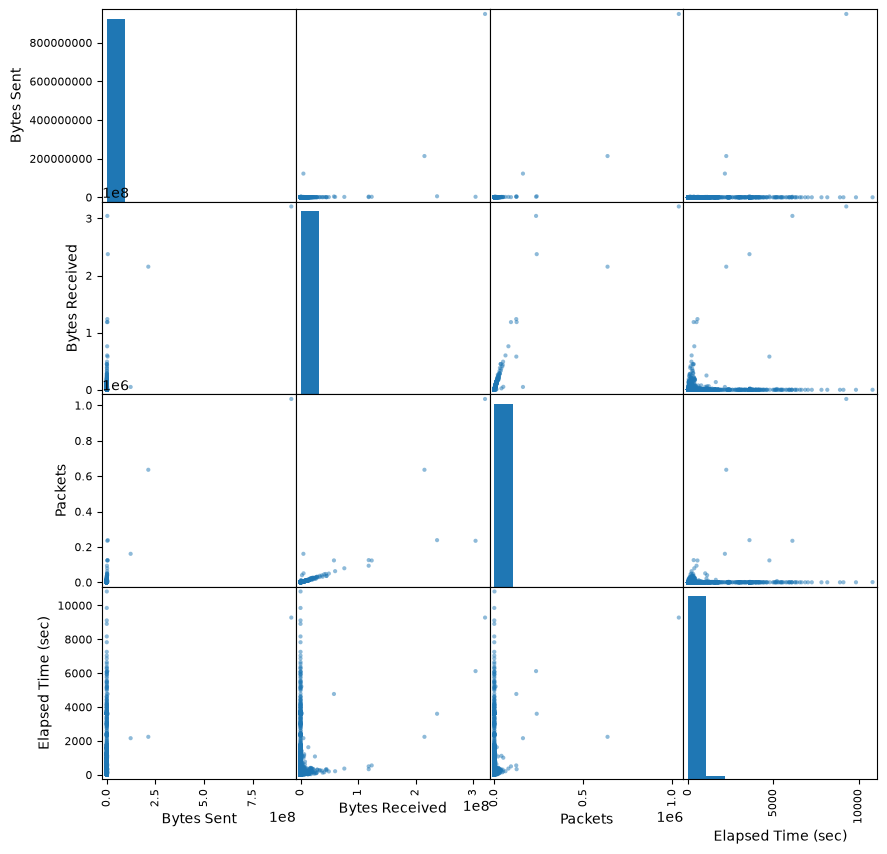

In [40]:
cols_to_plot = [
    'Bytes Sent',
    'Bytes Received',
    'Packets',
    'Elapsed Time (sec)'
]

subset_df = df[cols_to_plot]

scatter_matrix(
    subset_df,
    figsize=(10, 10),
    diagonal='hist'
)

plt.show()

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (45736, 11)
X_test shape: (11434, 11)
y_train shape: (45736,)
y_test shape: (11434,)


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

DataCleaning=Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

In [43]:
#train the model
DataCleaning.fit(X_train, y_train)

print('Random Forest training completed!')

Random Forest training completed!


In [44]:
#check training accuracy
from sklearn.metrics import accuracy_score

y_train_pred=DataCleaning.predict(X_train)

train_accuracy=accuracy_score(y_train, y_train_pred)

print('Training Accuracy:', train_accuracy)

Training Accuracy: 0.9998250830855344


In [45]:
#testing accuracy

y_pred=DataCleaning.predict(X_test)

test_accuracy=accuracy_score(y_test, y_pred)

print('Testing Accuracy:', test_accuracy)


Testing Accuracy: 0.9979884554836452


In [46]:
#cross validation
from sklearn.model_selection import cross_val_score

cv_scores=cross_val_score(
    DataCleaning,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print('Cross-Validation Scores:', cv_scores)
print('Mean CV Score:', cv_scores.mean())

Cross-Validation Scores: [0.99584609 0.99770417 0.99803214 0.99770417 0.99814147]
Mean CV Score: 0.9974856052019989


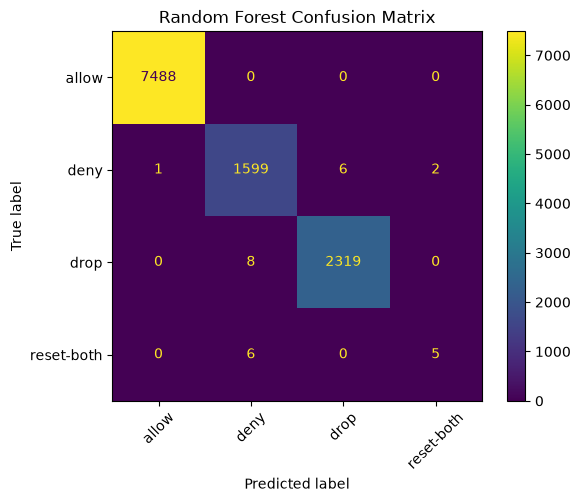

In [49]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm=confusion_matrix(y_test, y_pred, labels=DataCleaning.classes_)

display_cm=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=DataCleaning.classes_
)

display_cm.plot(xticks_rotation=45)
plt.title("Random Forest Confusion Matrix")
plt.show()

In [50]:
#Classification report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
    ))

              precision    recall  f1-score   support

       allow       1.00      1.00      1.00      7488
        deny       0.99      0.99      0.99      1608
        drop       1.00      1.00      1.00      2327
  reset-both       0.71      0.45      0.56        11

    accuracy                           1.00     11434
   macro avg       0.93      0.86      0.89     11434
weighted avg       1.00      1.00      1.00     11434



In [51]:
#Display feature importance

rf_model = DataCleaning.named_steps['model']

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
1,Destination Port,0.334898
8,Elapsed Time (sec),0.128326
4,Bytes,0.113812
0,Source Port,0.109816
5,Bytes Sent,0.092682
6,Bytes Received,0.072802
3,NAT Destination Port,0.060876
2,NAT Source Port,0.046443
7,Packets,0.023397
10,pkts_received,0.011905


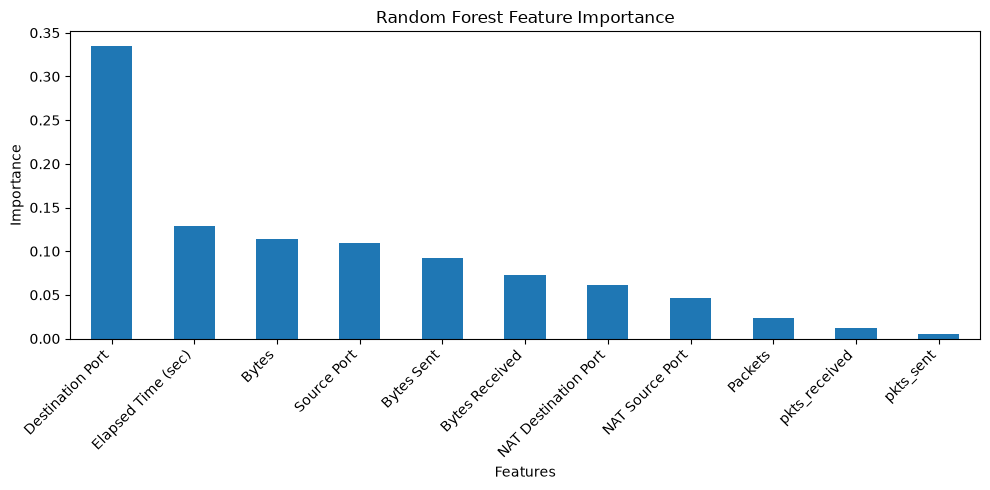

In [52]:
#visualize feature importance

feature_importance.plot(
    x='Feature',
    y='Importance',
    kind='bar',
    legend=False,
    figsize=(10, 5)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [53]:
#Summarize the model's performance

results = pd.DataFrame({
    'Metric': [
        'Training Accuracy',
        'Testing Accuracy',
        'Mean Cross-Validation Accuracy'
    ],
    'Score': [
        train_accuracy,
        test_accuracy,
        cv_scores.mean()
    ]
})

display(results)

,Metric,Score
0,Training Accuracy,0.999825
1,Testing Accuracy,0.997988
2,Mean Cross-Validation Accuracy,0.997486


In [54]:
import joblib
from pathlib import Path

# Create a folder for the saved model
Path("model").mkdir(exist_ok=True)

# Save the trained model
joblib.dump(rf_model, "model/firewall_random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [55]:
import joblib

model = joblib.load("model/firewall_random_forest.pkl")

print("Model type:", type(DataCleaning))
print("Feature names:", list(DataCleaning.feature_names_in_))
print("Classes:", list(DataCleaning.classes_))

Model type: <class 'sklearn.pipeline.Pipeline'>
Feature names: ['Source Port', 'Destination Port', 'NAT Source Port', 'NAT Destination Port', 'Bytes', 'Bytes Sent', 'Bytes Received', 'Packets', 'Elapsed Time (sec)', 'pkts_sent', 'pkts_received']
Classes: ['allow', 'deny', 'drop', 'reset-both']
